In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


In [3]:
df = pd.read_csv("D:\\AI-Based Hiring Prediction System\\AI-Based Hiring Prediction System (2).csv")

In [4]:
df.head()

,Resume_ID,Name,Skills,Experience (Years),Education,Certifications,Job Role,Recruiter Decision,Salary Expectation ($),Projects Count,AI Score (0-100)
0,1,Ashley Ali,"TensorFlow, NLP, Pytorch",10,B.Sc,NaN,AI Researcher,Hire,104895,8,100
1,2,Wesley Roman,"Deep Learning, Machine Learning, Python, SQL",10,MBA,Google ML,Data Scientist,Hire,113002,1,100
2,3,Corey Sanchez,"Ethical Hacking, Cybersecurity, Linux",1,MBA,Deep Learning Specialization,Cybersecurity Analyst,Hire,71766,7,70
3,4,Elizabeth Carney,"Python, Pytorch, TensorFlow",7,B.Tech,AWS Certified,AI Researcher,Hire,46848,0,95
4,5,Julie Hill,"SQL, React, Java",4,PhD,NaN,Software Engineer,Hire,87441,9,100


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Resume_ID               1000 non-null   int64
 1   Name                    1000 non-null   str  
 2   Skills                  1000 non-null   str  
 3   Experience (Years)      1000 non-null   int64
 4   Education               1000 non-null   str  
 5   Certifications          726 non-null    str  
 6   Job Role                1000 non-null   str  
 7   Recruiter Decision      1000 non-null   str  
 8   Salary Expectation ($)  1000 non-null   int64
 9   Projects Count          1000 non-null   int64
 10  AI Score (0-100)        1000 non-null   int64
dtypes: int64(5), str(6)
memory usage: 162.4 KB


In [6]:
df.isnull().sum()

Resume_ID                   0
Name                        0
Skills                      0
Experience (Years)          0
Education                   0
Certifications            274
Job Role                    0
Recruiter Decision          0
Salary Expectation ($)      0
Projects Count              0
AI Score (0-100)            0
dtype: int64

In [7]:
df["Recruiter Decision"].value_counts()

Recruiter Decision
Hire      812
Reject    188
Name: count, dtype: int64

In [8]:
df.describe()

,Resume_ID,Experience (Years),Salary Expectation ($),Projects Count,AI Score (0-100)
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,500.500000,4.896000,79994.486000,5.13300,83.950000
std,288.819436,3.112695,23048.472549,3.23137,20.983036
min,1.000000,0.000000,40085.000000,0.00000,15.000000
25%,250.750000,2.000000,60415.750000,2.00000,70.000000
50%,500.500000,5.000000,79834.500000,5.00000,100.000000
75%,750.250000,8.000000,99583.250000,8.00000,100.000000
max,1000.000000,10.000000,119901.000000,10.00000,100.000000


In [9]:
df["Certifications"] = df["Certifications"].fillna("No Certification")

In [10]:
df.isnull().sum()

Resume_ID                 0
Name                      0
Skills                    0
Experience (Years)        0
Education                 0
Certifications            0
Job Role                  0
Recruiter Decision        0
Salary Expectation ($)    0
Projects Count            0
AI Score (0-100)          0
dtype: int64

In [11]:
print("Education:")
print(df["Education"].unique())

print("\nJob Roles:")
print(df["Job Role"].unique())

print("\nRecruiter Decision:")
print(df["Recruiter Decision"].unique())

Education:
<ArrowStringArray>
['B.Sc', 'MBA', 'B.Tech', 'PhD', 'M.Tech']
Length: 5, dtype: str

Job Roles:
<ArrowStringArray>
['AI Researcher', 'Data Scientist', 'Cybersecurity Analyst',
 'Software Engineer']
Length: 4, dtype: str

Recruiter Decision:
<ArrowStringArray>
['Hire', 'Reject']
Length: 2, dtype: str


In [12]:
print("Sample Skills:")
print(df["Skills"].head(10).to_list())

print("\nSample Certifications:")
print(df["Certifications"].head(10).to_list())

Sample Skills:
['TensorFlow, NLP, Pytorch', 'Deep Learning, Machine Learning, Python, SQL', 'Ethical Hacking, Cybersecurity, Linux', 'Python, Pytorch, TensorFlow', 'SQL, React, Java', 'Cybersecurity, Networking, Linux, Ethical Hacking', 'Networking, Cybersecurity, Ethical Hacking', 'TensorFlow, Pytorch, NLP', 'Networking, Ethical Hacking', 'Python, TensorFlow, Pytorch, NLP']

Sample Certifications:
['No Certification', 'Google ML', 'Deep Learning Specialization', 'AWS Certified', 'No Certification', 'Google ML', 'AWS Certified', 'AWS Certified', 'Deep Learning Specialization', 'AWS Certified']


In [13]:
skills = set()

for skill_list in df["Skills"]:
    for skill in skill_list.split(","):
        skills.add(skill.strip())

print("Total unique skills:", len(skills))
print("\nSkills:")
print(sorted(skills))

Total unique skills: 14

Skills:
['C++', 'Cybersecurity', 'Deep Learning', 'Ethical Hacking', 'Java', 'Linux', 'Machine Learning', 'NLP', 'Networking', 'Python', 'Pytorch', 'React', 'SQL', 'TensorFlow']


In [14]:
# Get all unique skills
all_skills = sorted(skills)

# Create a column for every skill
for skill in all_skills:
    df[skill] = df["Skills"].apply(
        lambda x: 1 if skill in [s.strip() for s in x.split(",")] else 0
    )

df.head()

,Resume_ID,Name,Skills,Experience (Years),Education,Certifications,Job Role,Recruiter Decision,Salary Expectation ($),Projects Count,...,Java,Linux,Machine Learning,NLP,Networking,Python,Pytorch,React,SQL,TensorFlow
0,1,Ashley Ali,"TensorFlow, NLP, Pytorch",10,B.Sc,No Certification,AI Researcher,Hire,104895,8,...,0,0,0,1,0,0,1,0,0,1
1,2,Wesley Roman,"Deep Learning, Machine Learning, Python, SQL",10,MBA,Google ML,Data Scientist,Hire,113002,1,...,0,0,1,0,0,1,0,0,1,0
2,3,Corey Sanchez,"Ethical Hacking, Cybersecurity, Linux",1,MBA,Deep Learning Specialization,Cybersecurity Analyst,Hire,71766,7,...,0,1,0,0,0,0,0,0,0,0
3,4,Elizabeth Carney,"Python, Pytorch, TensorFlow",7,B.Tech,AWS Certified,AI Researcher,Hire,46848,0,...,0,0,0,0,0,1,1,0,0,1
4,5,Julie Hill,"SQL, React, Java",4,PhD,No Certification,Software Engineer,Hire,87441,9,...,1,0,0,0,0,0,0,1,1,0


In [15]:
df = pd.get_dummies(
    df,
    columns=["Education", "Job Role"],
    dtype=int
)

df.head()

,Resume_ID,Name,Skills,Experience (Years),Certifications,Recruiter Decision,Salary Expectation ($),Projects Count,AI Score (0-100),C++,...,TensorFlow,Education_B.Sc,Education_B.Tech,Education_M.Tech,Education_MBA,Education_PhD,Job Role_AI Researcher,Job Role_Cybersecurity Analyst,Job Role_Data Scientist,Job Role_Software Engineer
0,1,Ashley Ali,"TensorFlow, NLP, Pytorch",10,No Certification,Hire,104895,8,100,0,...,1,1,0,0,0,0,1,0,0,0
1,2,Wesley Roman,"Deep Learning, Machine Learning, Python, SQL",10,Google ML,Hire,113002,1,100,0,...,0,0,0,0,1,0,0,0,1,0
2,3,Corey Sanchez,"Ethical Hacking, Cybersecurity, Linux",1,Deep Learning Specialization,Hire,71766,7,70,0,...,0,0,0,0,1,0,0,1,0,0
3,4,Elizabeth Carney,"Python, Pytorch, TensorFlow",7,AWS Certified,Hire,46848,0,95,0,...,1,0,1,0,0,0,1,0,0,0
4,5,Julie Hill,"SQL, React, Java",4,No Certification,Hire,87441,9,100,0,...,0,0,0,0,0,1,0,0,0,1


In [16]:
df["Recruiter Decision"] = df["Recruiter Decision"].map({
    "Hire": 1,
    "Reject": 0
})

df["Recruiter Decision"].value_counts()

Recruiter Decision
1    812
0    188
Name: count, dtype: int64

In [17]:
df = pd.get_dummies(
    df,
    columns=["Certifications"],
    dtype=int
)

df.head()

,Resume_ID,Name,Skills,Experience (Years),Recruiter Decision,Salary Expectation ($),Projects Count,AI Score (0-100),C++,Cybersecurity,...,Education_MBA,Education_PhD,Job Role_AI Researcher,Job Role_Cybersecurity Analyst,Job Role_Data Scientist,Job Role_Software Engineer,Certifications_AWS Certified,Certifications_Deep Learning Specialization,Certifications_Google ML,Certifications_No Certification
0,1,Ashley Ali,"TensorFlow, NLP, Pytorch",10,1,104895,8,100,0,0,...,0,0,1,0,0,0,0,0,0,1
1,2,Wesley Roman,"Deep Learning, Machine Learning, Python, SQL",10,1,113002,1,100,0,0,...,1,0,0,0,1,0,0,0,1,0
2,3,Corey Sanchez,"Ethical Hacking, Cybersecurity, Linux",1,1,71766,7,70,0,1,...,1,0,0,1,0,0,0,1,0,0
3,4,Elizabeth Carney,"Python, Pytorch, TensorFlow",7,1,46848,0,95,0,0,...,0,0,1,0,0,0,1,0,0,0
4,5,Julie Hill,"SQL, React, Java",4,1,87441,9,100,0,0,...,0,1,0,0,0,1,0,0,0,1


In [18]:
# Features (inputs)
X = df.drop(
    columns=[
        "Resume_ID",
        "Name",
        "Skills",
        "Recruiter Decision"
    ]
)

# Target (what we want to predict)
y = df["Recruiter Decision"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 31)
y shape: (1000,)


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (800, 31)
Testing data: (200, 31)
Training labels: (800,)
Testing labels: (200,)


In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (800, 31)
X_test_scaled shape: (200, 31)


In [21]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [22]:
# Predict Hire/Reject for the test data
y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")
print("First 20 predictions:")
print(y_pred[:20])

Predictions generated successfully!
First 20 predictions:
[1 1 0 1 1 0 1 0 1 1 1 1 0 0 1 1 1 1 1 1]


In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-----------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

MODEL PERFORMANCE
-----------------
Accuracy : 97.0 %
Precision: 100.0 %
Recall   : 96.3 %
F1 Score : 98.11 %


In [24]:
from sklearn.metrics import classification_report

print("CLASSIFICATION REPORT")
print("---------------------")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Reject", "Hire"]
    )
)

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

      Reject       0.86      1.00      0.93        38
        Hire       1.00      0.96      0.98       162

    accuracy                           0.97       200
   macro avg       0.93      0.98      0.95       200
weighted avg       0.97      0.97      0.97       200



In [25]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 38   0]
 [  6 156]]


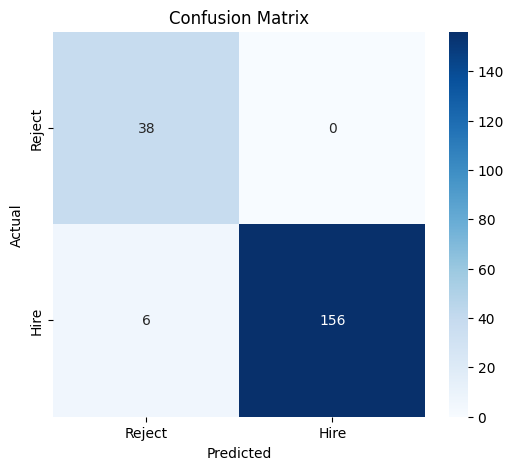

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Reject", "Hire"],
    yticklabels=["Reject", "Hire"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [27]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

feature_importance["Absolute Importance"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

print("Top 15 important features:")
feature_importance.head(15)

Top 15 important features:


,Feature,Coefficient,Absolute Importance
3,AI Score (0-100),5.335230,5.335230
0,Experience (Years),2.515095,2.515095
2,Projects Count,1.664315,1.664315
7,Ethical Hacking,0.487845,0.487845
24,Job Role_Cybersecurity Analyst,-0.378437,0.378437
17,TensorFlow,0.365767,0.365767
26,Job Role_Software Engineer,0.335114,0.335114
30,Certifications_No Certification,-0.312828,0.312828
8,Java,0.295084,0.295084
13,Python,0.283811,0.283811


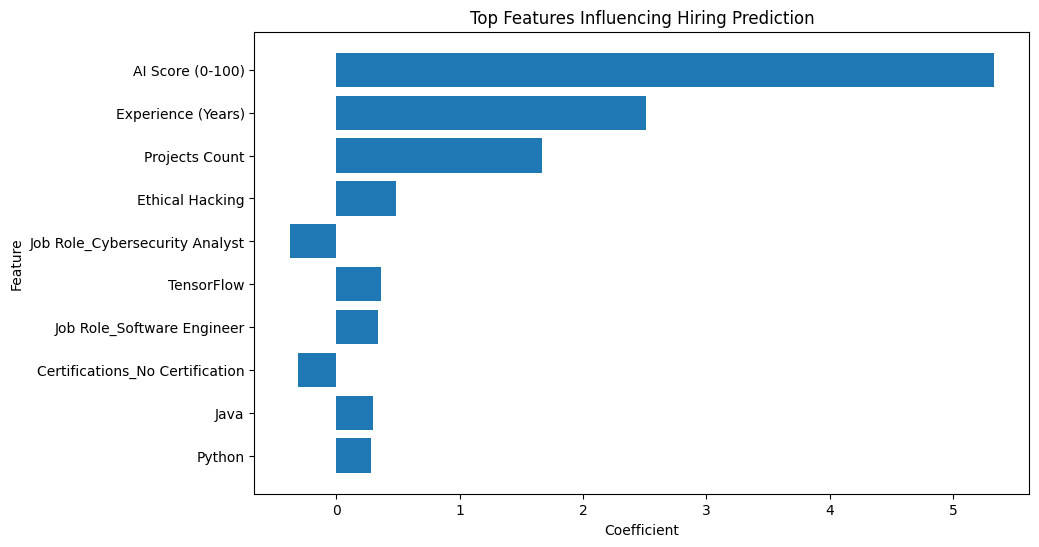

In [28]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Top Features Influencing Hiring Prediction")

plt.gca().invert_yaxis()

plt.show()

In [29]:
new_candidate = {
    "Experience (Years)": 4,
    "Salary Expectation ($)": 70000,
    "Projects Count": 5,

    "C++": 0,
    "Cybersecurity": 0,
    "Deep Learning": 1,
    "Ethical Hacking": 0,
    "Java": 0,
    "Linux": 0,
    "Machine Learning": 1,
    "NLP": 0,
    "Networking": 0,
    "Python": 1,
    "Pytorch": 1,
    "React": 0,
    "SQL": 1,
    "TensorFlow": 1,

    "Education_B.Sc": 0,
    "Education_B.Tech": 1,
    "Education_M.Tech": 0,
    "Education_MBA": 0,
    "Education_PhD": 0,

    "Job Role_AI Researcher": 0,
    "Job Role_Cybersecurity Analyst": 0,
    "Job Role_Data Scientist": 1,
    "Job Role_Software Engineer": 0,

    "Certifications_AWS Certified": 1,
    "Certifications_Deep Learning Specialization": 0,
    "Certifications_Google ML": 0,
    "Certifications_No Certification": 0
}

print("New candidate created.")

New candidate created.


In [30]:
new_candidate_df = pd.DataFrame([new_candidate])

# Make sure the columns are exactly the same
# as the columns used to train the model
new_candidate_df = new_candidate_df.reindex(
    columns=X.columns,
    fill_value=0
)

print("New candidate shape:", new_candidate_df.shape)

new_candidate_df

New candidate shape: (1, 31)


,Experience (Years),Salary Expectation ($),Projects Count,AI Score (0-100),C++,Cybersecurity,Deep Learning,Ethical Hacking,Java,Linux,...,Education_MBA,Education_PhD,Job Role_AI Researcher,Job Role_Cybersecurity Analyst,Job Role_Data Scientist,Job Role_Software Engineer,Certifications_AWS Certified,Certifications_Deep Learning Specialization,Certifications_Google ML,Certifications_No Certification
0,4,70000,5,0,0,0,1,0,0,0,...,0,0,0,0,1,0,1,0,0,0


In [31]:
new_candidate_scaled = scaler.transform(new_candidate_df)

print("New candidate scaled successfully!")

New candidate scaled successfully!


In [32]:
prediction = model.predict(new_candidate_scaled)[0]

if prediction == 1:
    print("Prediction: HIRE")
else:
    print("Prediction: REJECT")

Prediction: REJECT


In [33]:
probability = model.predict_proba(new_candidate_scaled)[0]

print("Reject Probability:", round(probability[0] * 100, 2), "%")
print("Hire Probability:", round(probability[1] * 100, 2), "%")

Reject Probability: 100.0 %
Hire Probability: 0.0 %


In [34]:
result = {
    "Prediction": "HIRE" if prediction == 1 else "REJECT",
    "Hire Probability": round(probability[1] * 100, 2),
    "Reject Probability": round(probability[0] * 100, 2)
}

result

{'Prediction': 'REJECT',
 'Hire Probability': np.float64(0.0),
 'Reject Probability': np.float64(100.0)}

In [35]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

feature_importance["Absolute Importance"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

print("Top 15 important features:")
display(feature_importance.head(15))

Top 15 important features:


,Feature,Coefficient,Absolute Importance
3,AI Score (0-100),5.335230,5.335230
0,Experience (Years),2.515095,2.515095
2,Projects Count,1.664315,1.664315
7,Ethical Hacking,0.487845,0.487845
24,Job Role_Cybersecurity Analyst,-0.378437,0.378437
17,TensorFlow,0.365767,0.365767
26,Job Role_Software Engineer,0.335114,0.335114
30,Certifications_No Certification,-0.312828,0.312828
8,Java,0.295084,0.295084
13,Python,0.283811,0.283811


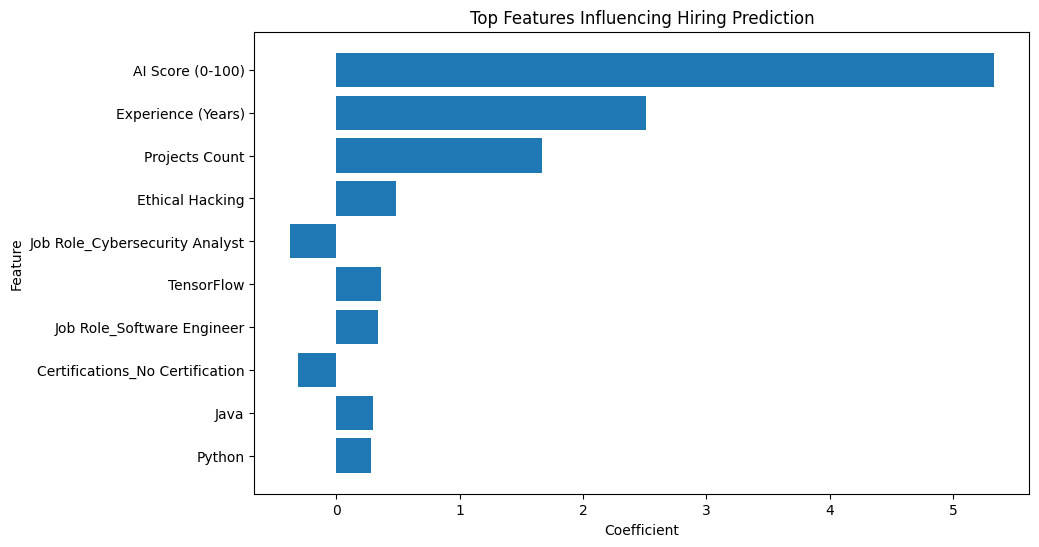

In [36]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Top Features Influencing Hiring Prediction")

plt.gca().invert_yaxis()

plt.show()

In [37]:
new_candidate = {
    "Experience (Years)": 4,
    "Salary Expectation ($)": 70000,
    "Projects Count": 5,

    "C++": 0,
    "Cybersecurity": 0,
    "Deep Learning": 1,
    "Ethical Hacking": 0,
    "Java": 0,
    "Linux": 0,
    "Machine Learning": 1,
    "NLP": 0,
    "Networking": 0,
    "Python": 1,
    "Pytorch": 1,
    "React": 0,
    "SQL": 1,
    "TensorFlow": 1,

    "Education_B.Sc": 0,
    "Education_B.Tech": 1,
    "Education_M.Tech": 0,
    "Education_MBA": 0,
    "Education_PhD": 0,

    "Job Role_AI Researcher": 0,
    "Job Role_Cybersecurity Analyst": 0,
    "Job Role_Data Scientist": 1,
    "Job Role_Software Engineer": 0,

    "Certifications_AWS Certified": 1,
    "Certifications_Deep Learning Specialization": 0,
    "Certifications_Google ML": 0,
    "Certifications_No Certification": 0
}

print("New candidate created successfully!")

New candidate created successfully!


In [38]:
new_candidate_df = pd.DataFrame([new_candidate])

new_candidate_df = new_candidate_df.reindex(
    columns=X.columns,
    fill_value=0
)

print("Candidate data prepared.")
print("Shape:", new_candidate_df.shape)

display(new_candidate_df)

Candidate data prepared.
Shape: (1, 31)


,Experience (Years),Salary Expectation ($),Projects Count,AI Score (0-100),C++,Cybersecurity,Deep Learning,Ethical Hacking,Java,Linux,...,Education_MBA,Education_PhD,Job Role_AI Researcher,Job Role_Cybersecurity Analyst,Job Role_Data Scientist,Job Role_Software Engineer,Certifications_AWS Certified,Certifications_Deep Learning Specialization,Certifications_Google ML,Certifications_No Certification
0,4,70000,5,0,0,0,1,0,0,0,...,0,0,0,0,1,0,1,0,0,0


In [39]:
new_candidate_scaled = scaler.transform(new_candidate_df)

print("Candidate data scaled successfully!")

Candidate data scaled successfully!


In [40]:
prediction = model.predict(new_candidate_scaled)[0]

if prediction == 1:
    print("Prediction: HIRE")
else:
    print("Prediction: REJECT")

Prediction: REJECT


In [41]:
probability = model.predict_proba(new_candidate_scaled)[0]

print("Reject Probability:", round(probability[0] * 100, 2), "%")
print("Hire Probability:", round(probability[1] * 100, 2), "%")

Reject Probability: 100.0 %
Hire Probability: 0.0 %


In [42]:
print("Raw probabilities:")
print(probability)

print("\nModel coefficients for this candidate:")
print(model.decision_function(new_candidate_scaled))

Raw probabilities:
[9.99999540e-01 4.60030972e-07]

Model coefficients for this candidate:
[-14.59197156]


In [43]:
candidate_effect = pd.DataFrame({
    "Feature": X.columns,
    "Candidate Value": new_candidate_df.iloc[0].values,
    "Coefficient": model.coef_[0]
})

candidate_effect["Contribution"] = (
    candidate_effect["Candidate Value"] *
    candidate_effect["Coefficient"]
)

candidate_effect["Absolute Contribution"] = (
    candidate_effect["Contribution"].abs()
)

candidate_effect = candidate_effect.sort_values(
    "Absolute Contribution",
    ascending=False
)

display(candidate_effect.head(15))

,Feature,Candidate Value,Coefficient,Contribution,Absolute Contribution
1,Salary Expectation ($),70000,0.180637,12644.599547,12644.599547
0,Experience (Years),4,2.515095,10.060380,10.060380
2,Projects Count,5,1.664315,8.321575,8.321575
17,TensorFlow,1,0.365767,0.365767,0.365767
13,Python,1,0.283811,0.283811,0.283811
6,Deep Learning,1,0.135304,0.135304,0.135304
14,Pytorch,1,-0.108815,-0.108815,0.108815
19,Education_B.Tech,1,-0.078726,-0.078726,0.078726
27,Certifications_AWS Certified,1,-0.073446,-0.073446,0.073446
16,SQL,1,0.071550,0.071550,0.071550


In [44]:
# Calculate contributions using the SCALED candidate values
candidate_effect = pd.DataFrame({
    "Feature": X.columns,
    "Scaled Value": new_candidate_scaled[0],
    "Coefficient": model.coef_[0]
})

candidate_effect["Contribution"] = (
    candidate_effect["Scaled Value"] *
    candidate_effect["Coefficient"]
)

candidate_effect["Absolute Contribution"] = (
    candidate_effect["Contribution"].abs()
)

candidate_effect = candidate_effect.sort_values(
    "Absolute Contribution",
    ascending=False
)

display(candidate_effect.head(15))

,Feature,Scaled Value,Coefficient,Contribution,Absolute Contribution
3,AI Score (0-100),-4.017279,5.335230,-21.433106,21.433106
0,Experience (Years),-0.303815,2.515095,-0.764124,0.764124
17,TensorFlow,1.925067,0.365767,0.704125,0.704125
13,Python,1.257237,0.283811,0.356817,0.356817
6,Deep Learning,2.229383,0.135304,0.301644,0.301644
7,Ethical Hacking,-0.498046,0.487845,-0.242969,0.242969
24,Job Role_Cybersecurity Analyst,-0.586973,-0.378437,0.222132,0.222132
14,Pytorch,1.984508,-0.108815,-0.215943,0.215943
30,Certifications_No Certification,-0.617813,-0.312828,0.193269,0.193269
26,Job Role_Software Engineer,-0.560026,0.335114,-0.187673,0.187673


In [45]:
X = df.drop(
    columns=[
        "Resume_ID",
        "Name",
        "Skills",
        "Recruiter Decision",
        "AI Score (0-100)"
    ],
    errors="ignore"
)

y = df["Recruiter Decision"]

print("X shape:", X.shape)
print("AI Score present:", "AI Score (0-100)" in X.columns)

X shape: (1000, 30)
AI Score present: False


In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (800, 30)
Testing: (200, 30)


In [47]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [48]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Model retrained successfully!")

Model retrained successfully!


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_pred = model.predict(X_test_scaled)

print("Accuracy :", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred) * 100, 2), "%")
print("Recall   :", round(recall_score(y_test, y_pred) * 100, 2), "%")
print("F1 Score :", round(f1_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Reject", "Hire"]
))

Accuracy : 96.0 %
Precision: 100.0 %
Recall   : 95.06 %
F1 Score : 97.47 %

Classification Report:
              precision    recall  f1-score   support

      Reject       0.83      1.00      0.90        38
        Hire       1.00      0.95      0.97       162

    accuracy                           0.96       200
   macro avg       0.91      0.98      0.94       200
weighted avg       0.97      0.96      0.96       200



In [50]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    max_depth=None
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [51]:
rf_pred = rf_model.predict(X_test)

print("Random Forest predictions generated!")

Random Forest predictions generated!


In [52]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print("RANDOM FOREST PERFORMANCE")
print("------------------------")
print("Accuracy :", round(rf_accuracy * 100, 2), "%")
print("Precision:", round(rf_precision * 100, 2), "%")
print("Recall   :", round(rf_recall * 100, 2), "%")
print("F1 Score :", round(rf_f1 * 100, 2), "%")

RANDOM FOREST PERFORMANCE
------------------------
Accuracy : 95.0 %
Precision: 95.78 %
Recall   : 98.15 %
F1 Score : 96.95 %


In [53]:
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=["Reject", "Hire"]
    )
)

              precision    recall  f1-score   support

      Reject       0.91      0.82      0.86        38
        Hire       0.96      0.98      0.97       162

    accuracy                           0.95       200
   macro avg       0.93      0.90      0.92       200
weighted avg       0.95      0.95      0.95       200



In [54]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.96,1.000000,0.950617,0.974684
1,Random Forest,0.95,0.957831,0.981481,0.969512


In [55]:
rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

display(rf_importance.head(15))

,Feature,Importance
0,Experience (Years),0.495938
2,Projects Count,0.202287
1,Salary Expectation ($),0.084153
29,Certifications_No Certification,0.014270
20,Education_MBA,0.012144
26,Certifications_AWS Certified,0.011582
21,Education_PhD,0.011520
17,Education_B.Sc,0.011205
27,Certifications_Deep Learning Specialization,0.011172
28,Certifications_Google ML,0.010828


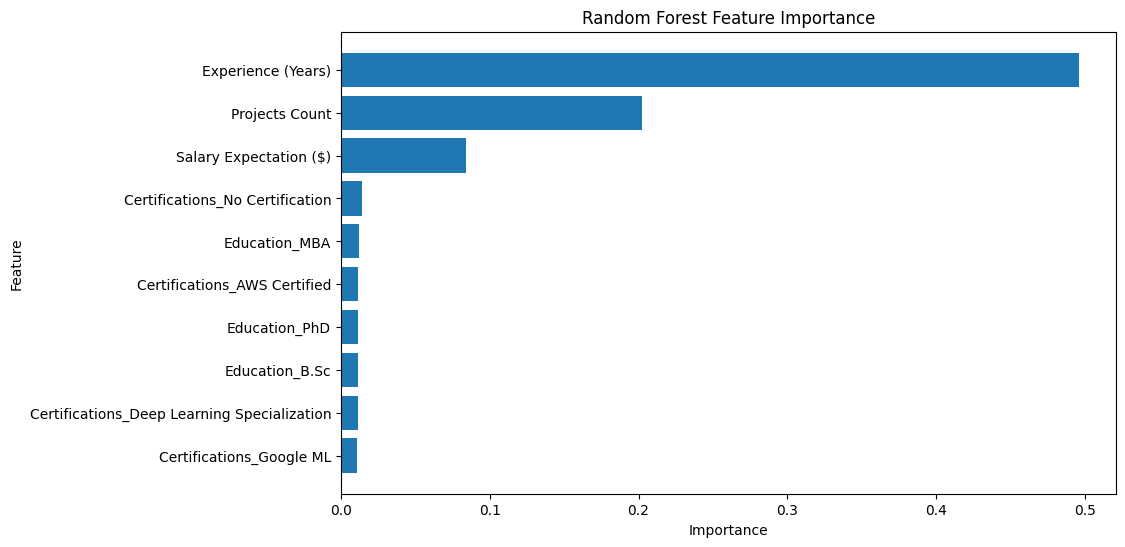

In [56]:
plt.figure(figsize=(10, 6))

top_rf_features = rf_importance.head(10)

plt.barh(
    top_rf_features["Feature"],
    top_rf_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.show()

In [57]:
import joblib

joblib.dump(model, "logistic_hiring_model.pkl")
joblib.dump(rf_model, "random_forest_hiring_model.pkl")
joblib.dump(scaler, "hiring_scaler.pkl")

print("Models and scaler saved successfully!")

Models and scaler saved successfully!


In [58]:
joblib.dump(list(X.columns), "model_features.pkl")

print("Feature list saved!")
print("Number of features:", len(X.columns))

Feature list saved!
Number of features: 30


In [59]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

lr_param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"]
}

lr_grid = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    param_grid=lr_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

lr_grid.fit(X_train_scaled, y_train)

print("Best parameters:")
print(lr_grid.best_params_)

print("\nBest 5-Fold Cross-Validation F1:")
print(round(lr_grid.best_score_, 4))

Best parameters:
{'C': 100, 'solver': 'lbfgs'}

Best 5-Fold Cross-Validation F1:
0.9884


In [60]:
best_lr_model = lr_grid.best_estimator_

tuned_lr_pred = best_lr_model.predict(X_test_scaled)

print("TUNED LOGISTIC REGRESSION")
print("------------------------")

print(
    "Accuracy :",
    round(accuracy_score(y_test, tuned_lr_pred) * 100, 2),
    "%"
)

print(
    "Precision:",
    round(precision_score(y_test, tuned_lr_pred) * 100, 2),
    "%"
)

print(
    "Recall   :",
    round(recall_score(y_test, tuned_lr_pred) * 100, 2),
    "%"
)

print(
    "F1 Score :",
    round(f1_score(y_test, tuned_lr_pred) * 100, 2),
    "%"
)

TUNED LOGISTIC REGRESSION
------------------------
Accuracy : 99.5 %
Precision: 100.0 %
Recall   : 99.38 %
F1 Score : 99.69 %


In [61]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ),
    param_grid=rf_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("\nBest 5-Fold Cross-Validation F1:")
print(round(rf_grid.best_score_, 4))

Best Random Forest parameters:
{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}

Best 5-Fold Cross-Validation F1:
0.9661


In [62]:
best_rf_model = rf_grid.best_estimator_

tuned_rf_pred = best_rf_model.predict(X_test)

print("TUNED RANDOM FOREST")
print("------------------")

print(
    "Accuracy :",
    round(accuracy_score(y_test, tuned_rf_pred) * 100, 2),
    "%"
)

print(
    "Precision:",
    round(precision_score(y_test, tuned_rf_pred) * 100, 2),
    "%"
)

print(
    "Recall   :",
    round(recall_score(y_test, tuned_rf_pred) * 100, 2),
    "%"
)

print(
    "F1 Score :",
    round(f1_score(y_test, tuned_rf_pred) * 100, 2),
    "%"
)

TUNED RANDOM FOREST
------------------
Accuracy : 95.0 %
Precision: 98.1 %
Recall   : 95.68 %
F1 Score : 96.88 %


In [63]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create a complete ML pipeline
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Use 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    lr_pipeline,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print("5-Fold F1 Scores:")
print(cv_scores)

print("\nMean F1 Score:",
      round(cv_scores.mean(), 4))

print("Standard Deviation:",
      round(cv_scores.std(), 4))

5-Fold F1 Scores:
[0.98442368 0.98757764 0.98432602 0.98432602 0.98113208]

Mean F1 Score: 0.9844
Standard Deviation: 0.002


In [64]:
print("Correlation with Recruiter Decision:")
print(
    df.select_dtypes(include=["number"])
      .corr()["Recruiter Decision"]
      .sort_values(ascending=False)
)

Correlation with Recruiter Decision:
Recruiter Decision                             1.000000
AI Score (0-100)                               0.840543
Experience (Years)                             0.576235
Projects Count                                 0.331249
React                                          0.048406
Salary Expectation ($)                         0.044073
Certifications_Google ML                       0.035325
Job Role_Software Engineer                     0.035139
TensorFlow                                     0.035123
Resume_ID                                      0.034135
C++                                            0.031381
NLP                                            0.030103
SQL                                            0.024173
Certifications_Deep Learning Specialization    0.023136
Education_B.Tech                               0.023035
Java                                           0.021905
Ethical Hacking                                0.017264
Education_P

In [65]:
X = df.drop(
    columns=[
        "Resume_ID",
        "Name",
        "Skills",
        "Recruiter Decision",
        "AI Score (0-100)"
    ],
    errors="ignore"
)

In [66]:
print("Hiring decision by Experience:")
print(
    df.groupby("Experience (Years)")["Recruiter Decision"]
      .agg(["count", "mean"])
)

print("\nHiring decision by Projects Count:")
print(
    df.groupby("Projects Count")["Recruiter Decision"]
      .agg(["count", "mean"])
)

Hiring decision by Experience:
                    count      mean
Experience (Years)                 
0                      89  0.235955
1                     102  0.460784
2                      82  0.560976
3                     106  0.783019
4                      80  0.925000
5                      95  1.000000
6                      99  1.000000
7                      93  1.000000
8                      91  1.000000
9                      86  1.000000
10                     77  1.000000

Hiring decision by Projects Count:
                count      mean
Projects Count                 
0                  95  0.715789
1                  82  0.585366
2                  94  0.670213
3                  77  0.662338
4                  95  0.715789
5                  89  0.842697
6                  77  0.805195
7                  91  0.912088
8                 100  0.950000
9                  92  0.989130
10                108  1.000000


In [67]:
print("Hiring decision by AI Score:")
print(
    df.groupby("AI Score (0-100)")["Recruiter Decision"]
      .agg(["count", "mean"])
)

Hiring decision by AI Score:
                  count  mean
AI Score (0-100)             
15                    2   0.0
20                    4   0.0
25                    4   0.0
30                   11   0.0
35                   18   0.0
40                   15   0.0
45                   30   0.0
50                   33   0.0
55                   27   0.0
60                   44   0.0
65                   39   1.0
70                   53   1.0
75                   36   1.0
80                   47   1.0
85                   46   1.0
90                   44   1.0
95                   44   1.0
100                 503   1.0


In [68]:
print(
    pd.crosstab(
        df["Experience (Years)"],
        df["Recruiter Decision"],
        margins=True
    )
)

Recruiter Decision    0    1   All
Experience (Years)                
0                    68   21    89
1                    55   47   102
2                    36   46    82
3                    23   83   106
4                     6   74    80
5                     0   95    95
6                     0   99    99
7                     0   93    93
8                     0   91    91
9                     0   86    86
10                    0   77    77
All                 188  812  1000


In [69]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

best_lr_pipeline = lr_grid.best_estimator_

print("Best Parameters:")
print(lr_grid.best_params_)

print("\nBest Cross-Validation F1:")
print(lr_grid.best_score_)

Best Parameters:
{'model__C': 100, 'model__solver': 'lbfgs'}

Best Cross-Validation F1:
0.989182927915887


In [70]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred = best_lr_pipeline.predict(X_test)

print("Final Logistic Regression Results")
print("----------------------------------")

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Reject", "Hire"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Final Logistic Regression Results
----------------------------------
Accuracy : 0.995
Precision: 1.0
Recall   : 0.9938271604938271
F1 Score : 0.9969040247678018

Classification Report:
              precision    recall  f1-score   support

      Reject       0.97      1.00      0.99        38
        Hire       1.00      0.99      1.00       162

    accuracy                           0.99       200
   macro avg       0.99      1.00      0.99       200
weighted avg       1.00      0.99      1.00       200

Confusion Matrix:
[[ 38   0]
 [  1 161]]


In [71]:
import joblib

# Save the complete preprocessing + Logistic Regression pipeline
joblib.dump(
    best_lr_pipeline,
    "final_hiring_prediction_pipeline.pkl"
)

# Save the exact feature names used by the model
joblib.dump(
    list(X.columns),
    "model_features.pkl"
)

print("Final model saved successfully!")
print("File: final_hiring_prediction_pipeline.pkl")
print("Features saved: model_features.pkl")

Final model saved successfully!
File: final_hiring_prediction_pipeline.pkl
Features saved: model_features.pkl
